<a href="https://colab.research.google.com/github/jenipherorishaba2-ship-it/nlp_project/blob/main/stanford_sentimental_analysis_nlp_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**IMDb Sentiment Analysis Using Natural Language Processing**

Introduction

This project uses Natural Language Processing (NLP) and machine learning to classify IMDb movie reviews as positive or negative.

The project uses the IMDb dataset from Stanford NLP, TF-IDF for text feature extraction, and Logistic Regression for sentiment classification. GridSearchCV is used to improve the model's settings.

**Objectives**

Explore and understand the dataset.

Train a sentiment analysis model.

Evaluate the model's performance.

Improve the model using hyperparameter tuning.

Save and test the trained model.

loading the the IMDb dataset

In [30]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb")

ds

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

importing the libraries

In [31]:
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score
)

Convert the dataset to pandas

In [32]:


train= ds["train"].to_pandas()
test= ds["test"].to_pandas()
print(train.shape, test.shape)
train.head()

(25000, 2) (25000, 2)


,text,label
0,"I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered ""controversial"" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, even then it's not shot like some cheaply made porno. While my countrymen mind find it shocking, in reality sex and nudity are a major staple in Swedish cinema. Even Ingmar Bergman, arguably their answer to good old boy John Ford, had sex scenes in his films.<br /><br />I do commend the filmmakers for the fact that any sex shown in the film is shown for artistic purposes rather than just to shock people and make money to be shown in pornographic theaters in America. I AM CURIOUS-YELLOW is a good film for anyone wanting to study the meat and potatoes (no pun intended) of Swedish cinema. But really, this film doesn't have much of a plot.",0
1,"""I Am Curious: Yellow"" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where are the R-rated films with gaping vulvas and flapping labia? Nowhere, because they don't exist. The same goes for those crappy cable shows: schlongs swinging in the breeze but not a clitoris in sight. And those pretentious indie movies like The Brown Bunny, in which we're treated to the site of Vincent Gallo's throbbing johnson, but not a trace of pink visible on Chloe Sevigny. Before crying (or implying) ""double-standard"" in matters of nudity, the mentally obtuse should take into account one unavoidably obvious anatomical difference between men and women: there are no genitals on display when actresses appears nude, and the same cannot be said for a man. In fact, you generally won't see female genitals in an American film in anything short of porn or explicit erotica. This alleged double-standard is less a double standard than an admittedly depressing ability to come to terms culturally with the insides of women's bodies.",0
2,"If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no cogent story.<br /><br />One might feel virtuous for sitting thru it because it touches on so many IMPORTANT issues but it does so without any discernable motive. The viewer comes away with no new perspectives (unless one comes up with one while one's mind wanders, as it will invariably do during this pointless film).<br /><br />One might better spend one's time staring out a window at a tree growing.<br /><br />",0
3,"This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead.<br /><br />The film has two strong elements and those are, (1) the realistic acting (2) the impressive, undeservedly good, photo. Apart from that, what strikes me most is the endless stream of silliness. Lena Nyman has to be most annoying actress in the world. She acts so stupid and with all the nudity in this film,...it's unattractive. Comparing to Godard's film, intellectuality has been r

check if the dataset is balanced (postives or negatives)

In [33]:

print("Training Set Label Distribution:")
print(train['label'].value_counts())
print("\nTesting Set Label Distribution:")
print(test['label'].value_counts())

Training Set Label Distribution:
label
0    12500
1    12500
Name: count, dtype: int64

Testing Set Label Distribution:
label
0    12500
1    12500
Name: count, dtype: int64


checking the length of each review

the reviews summary

In [34]:
train ["n_words"]= train["text"].str.split().str.len()
print(train["n_words"].describe())

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: n_words, dtype: float64


In [6]:
# Display a few positive and negative reviews
pd.set_option('display.max_colwidth', None)

print("=== Example Positive Reviews ===")
display(train[train['label'] == 1]['text'].head(3))

print("\n=== Example Negative Reviews ===")
display(train[train['label'] == 0]['text'].head(3))

=== Example Positive Reviews ===


,text
12500,"Zentropa has much in common with The Third Man, another noir-like film set among the rubble of postwar Europe. Like TTM, there is much inventive camera work. There is an innocent American who gets emotionally involved with a woman he doesn't really understand, and whose naivety is all the more striking in contrast with the natives.<br /><br />But I'd have to say that The Third Man has a more well-crafted storyline. Zentropa is a bit disjointed in this respect. Perhaps this is intentional: it is presented as a dream/nightmare, and making it too coherent would spoil the effect. <br /><br />This movie is unrelentingly grim--""noir"" in more than one sense; one never sees the sun shine. Grim, but intriguing, and frightening."
12501,"Zentropa is the most original movie I've seen in years. If you like unique thrillers that are influenced by film noir, then this is just the right cure for all of those Hollywood summer blockbusters clogging the theaters these days. Von Trier's follow-ups like Breaking the Waves have gotten more acclaim, but this is really his best work. It is flashy without being distracting and offers the perfect combination of suspense and dark humor. It's too bad he decided handheld cameras were the wave of the future. It's hard to say who talked him away from the style he exhibits here, but it's everyone's loss that he went into his heavily theoretical dogma direction instead."
12502,"Lars Von Trier is never backward in trying out new techniques. Some of them are very original while others are best forgotten.<br /><br />He depicts postwar Germany as a nightmarish train journey. With so many cities lying in ruins, Leo Kessler a young American of German descent feels obliged to help in their restoration. It is not a simple task as he quickly finds out.<br /><br />His uncle finds him a job as a night conductor on the Zentropa Railway Line. His job is to attend to the needs of the passengers. When the shoes are polished a chalk mark is made on the soles. A terrible argument ensues when a passenger's shoes are not chalked despite the fact they have been polished. There are many allusions to the German fanaticism of adherence to such stupid details.<br /><br />The railway journey is like an allegory representing man's procession through life with all its trials and tribulations. In one sequence Leo dashes through the back carriages to discover them filled with half-starved bodies appearing to have just escaped from Auschwitz . These images, horrible as they are, are fleeting as in a dream, each with its own terrible impact yet unconnected.<br /><br />At a station called Urmitz Leo jumps from the train with a parceled bomb. In view of many by-standers he connects the bomb to the underside of a carriage. He returns to his cabin and makes a connection to a time clock. Later he jumps from the train (at high speed) and lies in the cool grass on a river bank. Looking at the stars above he decides that his job is to build and not destroy. Subsequently as he sees the train approaching a giant bridge he runs at breakneck speed to board the train and stop the clock. If you care to analyse the situation it is a completely impossible task. Quite ridiculous in fact. It could only happen in a dream.<br /><br />It's strange how one remembers little details such as a row of cups hanging on hooks and rattling away with the swaying of the train.<br /><br />Despite the fact that this film is widely acclaimed, I prefer Lars Von Trier's later films (Breaking the Waves and The Idiots). The bomb scene described above really put me off. Perhaps I'm a realist."



=== Example Negative Reviews ===


,text
0,"I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered ""controversial"" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, even then it's not shot like some cheaply made porno. While my countrymen mind find it shocking, in reality sex and nudity are a major staple in Swedish cinema. Even Ingmar Bergman, arguably their answer to good old boy John Ford, had sex scenes in his films.<br /><br />I do commend the filmmakers for the fact that any sex shown in the film is shown for artistic purposes rather than just to shock people and make money to be shown in pornographic theaters in America. I AM CURIOUS-YELLOW is a good film for anyone wanting to study the meat and potatoes (no pun intended) of Swedish cinema. But really, this film doesn't have much of a plot."
1,"""I Am Curious: Yellow"" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where are the R-rated films with gaping vulvas and flapping labia? Nowhere, because they don't exist. The same goes for those crappy cable shows: schlongs swinging in the breeze but not a clitoris in sight. And those pretentious indie movies like The Brown Bunny, in which we're treated to the site of Vincent Gallo's throbbing johnson, but not a trace of pink visible on Chloe Sevigny. Before crying (or implying) ""double-standard"" in matters of nudity, the mentally obtuse should take into account one unavoidably obvious anatomical difference between men and women: there are no genitals on display when actresses appears nude, and the same cannot be said for a man. In fact, you generally won't see female genitals in an American film in anything short of porn or explicit erotica. This alleged double-standard is less a double standard than an admittedly depressing ability to come to terms culturally with the insides of women's bodies."
2,"If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no cogent story.<br /><br />One might feel virtuous for sitting thru it because it touches on so many IMPORTANT issues but it does so without any discernable motive. The viewer comes away with no new perspectives (unless one comes up with one while one's mind wanders, as it will invariably do during this pointless film).<br /><br />One might better spend one's time staring out a window at a tree growing.<br /><br />"


Select training and testing samples

In [7]:
N_TRAIN =7000
N_TEST = 2000

train_sample = train.sample(n=N_TRAIN, random_state=0)
test_sample = test.sample(n=N_TEST, random_state=42)


These imports are to work  on this from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

Build and train the original model

In [35]:

# Prepare the training and testing data
X_train = train_sample["text"].astype(str)
y_train = train_sample["label"]

X_test = test_sample["text"].astype(str)
y_test = test_sample["label"]

# Build the machine-learning pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))


Model training completed!
Accuracy: 0.872

Classification Report:
              precision    recall  f1-score   support

    Negative       0.88      0.87      0.88      1040
    Positive       0.86      0.87      0.87       960

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



 TF-IDF: Converts the review text into numerical features.
 Logistic Regression: Learns patterns associated with positive and negative reviews.
 Prediction: Predicts the sentiment of reviews it has not trained on.
 Evaluation: Measures how well the model performs.
 The pipeline also ensures that TF-IDF is fitted on the training reviews only, preventing information from the test set from leaking into training.

Evaluating the original model

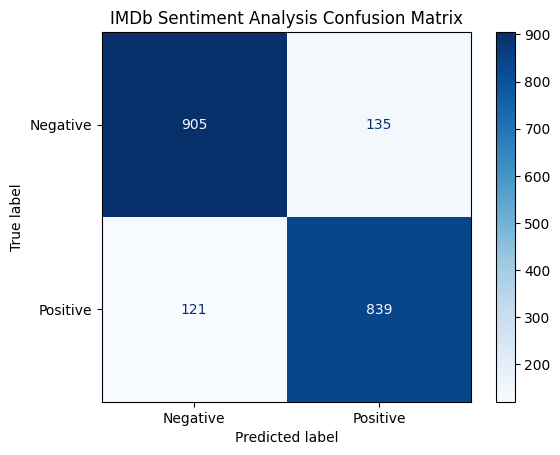

In [36]:



ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("IMDb Sentiment Analysis Confusion Matrix")
plt.show()


Top-left (905): The model correctly identified 905 negative reviews.



Top-right (135): It mistakenly classified 135 negative reviews as positive.



Bottom-left (121): It mistakenly classified 121 positive reviews as negative.



Bottom-right (839): The model correctly identified 839 positive reviews.

Test the model on new reviews

In [10]:

new_reviews = [
    "This movie was fantastic and I really enjoyed it.",
    "The movie was boring and a complete waste of time.",
    "The acting was excellent but the story was disappointing."
]

predictions = model.predict(new_reviews)

for review, prediction in zip(new_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("-" * 50)


Review: This movie was fantastic and I really enjoyed it.
Predicted sentiment: Positive
--------------------------------------------------
Review: The movie was boring and a complete waste of time.
Predicted sentiment: Negative
--------------------------------------------------
Review: The acting was excellent but the story was disappointing.
Predicted sentiment: Positive
--------------------------------------------------


The third review contains both positive and negative opinions. The acting was excellent, but the story was disappointing. This model is classifying the whole sentence as positive, even though the negative part is important.

This is an example of a limitation of sentiment analysis: a model can struggle with mixed opinions, contrast words such as “but,” and the relationship between different parts of a sentence.

Investigating the third review

In [11]:

reviews = [
    "This movie was fantastic and I really enjoyed it.",
    "The movie was boring and a complete waste of time.",
    "The acting was excellent but the story was disappointing."
]

probabilities = model.predict_proba(reviews)
predictions = model.predict(reviews)

for review, prediction, probability in zip(
    reviews, predictions, probabilities
):
    print("Review:", review)
    print("Prediction:", "Positive" if prediction == 1 else "Negative")
    print(f"Negative probability: {probability[0]:.2%}")
    print(f"Positive probability: {probability[1]:.2%}")
    print("-" * 60)


Review: This movie was fantastic and I really enjoyed it.
Prediction: Positive
Negative probability: 15.70%
Positive probability: 84.30%
------------------------------------------------------------
Review: The movie was boring and a complete waste of time.
Prediction: Negative
Negative probability: 94.74%
Positive probability: 5.26%
------------------------------------------------------------
Review: The acting was excellent but the story was disappointing.
Prediction: Positive
Negative probability: 46.12%
Positive probability: 53.88%
------------------------------------------------------------


 Improve the model using GridSearchCVmodel

In [37]:


# Use the pipeline we already created
parameters = {
    "classifier__C": [0.1, 1, 10]
}

search = GridSearchCV(
    estimator=model,
    param_grid=parameters,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

# Find the best settings using training data only
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Best cross-validation F1-score:",
      round(search.best_score_, 4))

# Keep the best model
best_model = search.best_estimator_


Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best settings: {'classifier__C': 10}
Best cross-validation F1-score: 0.8779


Evaluate the improved model fairly

In [38]:


# Evaluate the tuned model on the held-out test set
y_pred_tuned = best_model.predict(X_test)

print("Tuned Model Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned), 4))

print("\nTuned Model Classification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Negative", "Positive"]
))


Tuned Model Accuracy: 0.88

Tuned Model Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.88      0.88      1040
    Positive       0.87      0.88      0.88       960

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



Update the confusion matrix

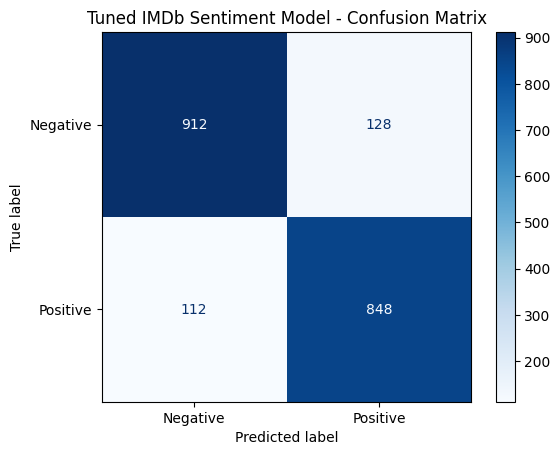

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("Tuned IMDb Sentiment Model - Confusion Matrix")
plt.show()


compareing the performance of the original model with the improved (tuned) model to see whether tuning made the model better.

In [39]:


comparison = pd.DataFrame({
    "Model": ["Original Model", "Tuned Model"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_tuned)
    ],
    "Macro F1-score": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(y_test, y_pred_tuned, average="macro")
    ]
})

display(comparison.round(4))

,Model,Accuracy,Macro F1-score
0,Original Model,0.872,0.8719
1,Tuned Model,0.880,0.8799


saving the improved model

In [16]:

# Save the improved model
joblib.dump(best_model, "imdb_sentiment_model.pkl")

print("Your improved sentiment analysis model has been saved!")

Your improved sentiment analysis model has been saved!


confirming that the saved model can be loaded and used

In [45]:

# Load the saved model
loaded_model = joblib.load("/content/imdb_sentiment_model.pkl")

# Test new reviews
reviews = [
    "This movie was fantastic and enjoyable.",
    "This movie was terrible and boring.",
    "Terrible experience, I want my money back.",
]

predictions = loaded_model.predict(reviews)

for review, prediction in zip(reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("-" * 40)


Review: This movie was fantastic and enjoyable.
Predicted sentiment: Positive
----------------------------------------
Review: This movie was terrible and boring.
Predicted sentiment: Negative
----------------------------------------
Review: Terrible experience, I want my money back.
Predicted sentiment: Negative
----------------------------------------


checking of the the classes my first model can predict

In [26]:
print("Classes:", model.classes_)

Classes: [0 1]


checking of the the classes my improved model can predict

In [46]:
print("Classes:", best_model.classes_)

Classes: [0 1]


checking if the model exists

In [42]:
model_path = "/content/imdb_sentiment_model.pkl"

if os.path.exists(model_path):
    print("Model exists!")
    print("File size:", round(
        os.path.getsize(model_path) / 1024, 2
    ), "KB")
else:
    print("Model file not found.")

Model exists!
File size: 903.18 KB


## Conclusion

In this project, I developed an IMDb sentiment analysis model using TF-IDF vectorization and Logistic Regression. I explored the dataset, checked the class distribution, examined review lengths, and evaluated the model using accuracy, precision, recall, F1-score and a confusion matrix.

I improved the original model using GridSearchCV, which selected a Logistic Regression parameter of C=10. The tuned model achieved **88% accuracy** on a separate test set of 2,000 reviews. I also tested the model on new reviews and saved the trained pipeline as `imdb_sentiment_model.pkl` using Joblib.

Although the model performs well on many reviews, it can struggle with mixed opinions and complex sentence meanings. Future improvements could include testing additional model settings, comparing other classification algorithms, and evaluating more diverse reviews.